# Đánh giá: kết quả chính, ablation, độ tin cậy, chi phí, 3B và 7B

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd().parent / "src"))

from sva.config import RESULTS_DIR, TASK_IDS
from sva.eval import accuracy, correct, load_predictions, mcnemar, reliability

BLUE, ORANGE, AQUA, GRAY, DARK = "#2a78d6", "#eb6834", "#1baf7a", "#b5b4ae", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 90})
SYSTEMS = {"B0-local": "b0_local", "B0 + vòng lặp": "b0_loop", "B0-api (Gemini)": "b0_api", "B1-vanilla": "b1_vanilla",
           "SVA": "sva"}
COLORS = {"B0-local": GRAY, "B0 + vòng lặp": "#d8d6cf", "B0-api (Gemini)": ORANGE, "B1-vanilla": DARK, "SVA": BLUE}
P = {n: {t: load_predictions(s, t, "test") for t in TASK_IDS} for n, s in SYSTEMS.items()}
TABLES = RESULTS_DIR / "tables"

## 1. Kết quả chính (bản 3B)

In [2]:
display(Markdown((TABLES / "main_results.md").read_text(encoding="utf-8")))

# Kết quả chính (tập test, Qwen2.5-VL-3B-Instruct 4-bit)

| Task | n | B0-local | B0 + vòng lặp | B0-api (Gemini) | B1-vanilla | SVA | Δ SVA − B1 | SVA đúng & B1 sai / ngược lại | p (McNemar) | paper: Qwen2.5-VL-7B | paper: SoccerAgent |
|---|---|---|---|---|---|---|---|---|---|---|---|
| q8 (Q7) | 280 | 45,4 | 52,5 | **68,9** | 45,0 | 58,9 | 13,9 | 82 / 43 | < 0,001 | 56,8 | 51,1 |
| q9 (Q8) | 280 | 27,5 | 25,0 | 32,5 | 25,7 | **78,9** | 53,2 | 164 / 15 | < 0,001 | 31,6 | 35,7 |
| q10 (Q9) | 700 | 36,1 | 37,4 | 64,4 | 74,6 | **87,1** | 12,6 | 102 / 14 | < 0,001 | 52,2 | 85,0 |
| q11 (Q10) | 700 | 31,3 | 37,9 | 70,1 | 31,4 | **74,3** | 42,9 | 350 / 50 | < 0,001 | 51,6 | 72,9 |
| q13 (Q12) | 490 | 45,9 | 46,1 | **48,8** | 46,3 | 46,5 | 0,2 | 60 / 59 | 1,000 | 46,9 | 46,0 |
| q14 (Q13) | 192 | 56,8 | 57,3 | **79,2** | 45,3 | 60,4 | 15,1 | 55 / 26 | 0,002 | 50,7 | 55,5 |
| **Trung bình 6 task** |  | 40,5 | 42,7 | 60,7 | 44,7 | 67,7 | 23,0 |  |  | 48,3 | 57,7 |
| **Trung bình bỏ q10, q11** |  | 43,9 | 45,2 | 57,3 | 40,6 | 61,2 | 20,6 |  |  | 46,5 | 47,1 |

- n: số câu test (chia dev/test theo nhóm nội dung; q14 còn 276 câu sau khi bỏ 24 câu lỗi, test 192).
- B0-local, B1, SVA dùng cùng Qwen2.5-VL-3B-Instruct 4-bit và cùng frame (8 frame một clip, tối đa 24 frame một câu).
- Cột paper: số công bố của SoccerAgent (Qwen2.5-VL-7B, cả video, toàn bộ 10 nghìn câu): **khác giao thức, chỉ để tham khảo, không so trực tiếp**.
- q10, q11 dùng Action Classifier của UniSoccer, được huấn luyện trên SoccerReplay-1988 — nguồn của clip q10: có thể trùng dữ liệu huấn luyện công cụ; so với B1 vẫn công bằng (cùng công cụ).


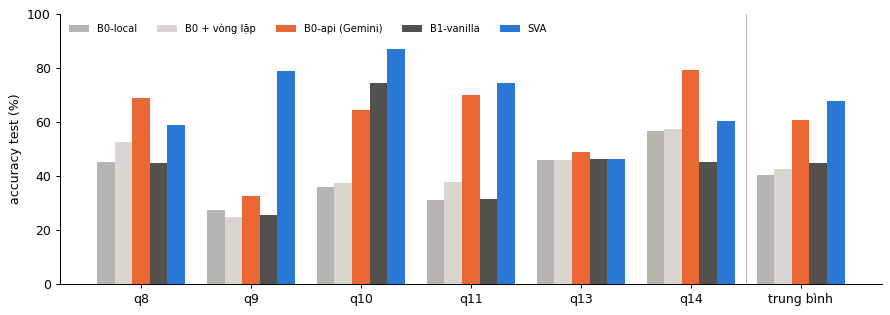

SVA hơn B1 có ý nghĩa (p < 0,05) ở 5/6 task


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(TASK_IDS) + 1); w = 0.16
for j, n in enumerate(SYSTEMS):
    vals = [100 * accuracy(P[n][t]) for t in TASK_IDS]
    vals.append(np.mean(vals))
    ax.bar(x + (j - 2) * w, vals, w, color=COLORS[n], label=n)
ax.axvline(len(TASK_IDS) - 0.5, color=GRAY, lw=0.8)
ax.set_xticks(x, TASK_IDS + ["trung bình"]); ax.set_ylabel("accuracy test (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=5, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
sig = sum(mcnemar(P["B1-vanilla"][t], P["SVA"][t])["p_value"] < 0.05 for t in TASK_IDS)
print(f"SVA hơn B1 có ý nghĩa (p < 0,05) ở {sig}/6 task")

## 2. Ablation

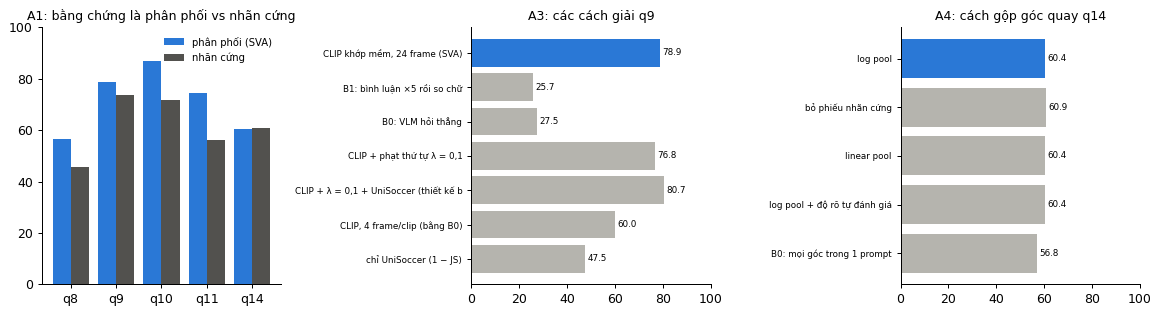

In [4]:
ab = json.loads((RESULTS_DIR / "ablation" / "summary.json").read_text(encoding="utf-8"))
def group(prefix):
    return {k.split(" | ")[1]: v for k, v in ab.items() if k.startswith(prefix)}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
a1 = {t: group(f"A1 · {t}") for t in ["q8", "q9", "q10", "q11", "q14"]}
soft = [list(v.values())[0] for v in a1.values()]; hard = [list(v.values())[1] for v in a1.values()]
x = np.arange(len(a1))
axes[0].bar(x - 0.2, soft, 0.4, color=BLUE, label="phân phối (SVA)"); axes[0].bar(x + 0.2, hard, 0.4, color=DARK, label="nhãn cứng")
axes[0].set_xticks(x, list(a1)); axes[0].set_ylim(0, 100); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("A1: bằng chứng là phân phối vs nhãn cứng", fontsize=10)
for ax, prefix, title in [(axes[1], "A3 · q9", "A3: các cách giải q9"), (axes[2], "A4 · q14", "A4: cách gộp góc quay q14")]:
    g = group(prefix)
    ax.barh(range(len(g)), list(g.values()), color=[BLUE] + [GRAY] * (len(g) - 1))
    ax.set_yticks(range(len(g)), [k[:38] for k in g], fontsize=7); ax.invert_yaxis(); ax.set_xlim(0, 100)
    for i, v in enumerate(g.values()):
        ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=7)
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

In [5]:
display(Markdown((TABLES / "ablation_test.md").read_text(encoding="utf-8")))

# Ablation (tập test, backend qwen_local_3b)

Mọi cấu hình của SVA chọn trên dev; bảng này chỉ đo trên test. McNemar so với dòng **in đậm** của cùng nhóm (b = biến thể đúng & mốc sai, c = ngược lại). Hòa phiếu thì chọn ngẫu nhiên (seed 0) trong các phương án hòa.

## A1 · q8: phân phối vs nhãn cứng

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **phân phối (SVA không vòng lặp)** | 280 | 56,4 | — | — |
| nhãn cứng | 280 | 45,7 | 35 / 65 | 0,0037 |

## A1 · q9: phân phối vs nhãn cứng

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **điểm khớp mềm (SVA)** | 280 | 78,9 | — | — |
| mỗi frame bầu 1 phiếu | 280 | 73,9 | 5 / 19 | 0,0066 |

## A1 · q10: phân phối vs nhãn cứng

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **phân phối (SVA)** | 700 | 87,1 | — | — |
| chỉ nhãn top-1 của UniSoccer | 700 | 71,9 | 12 / 119 | 0,0000 |

## A1 · q11: phân phối vs nhãn cứng

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **phân phối (SVA)** | 700 | 74,3 | — | — |
| top-1 video == top-1 câu bình luận | 700 | 56,0 | 45 / 173 | 0,0000 |

## A1 · q14: phân phối vs nhãn cứng

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **log pool (SVA)** | 192 | 60,4 | — | — |
| bỏ phiếu nhãn cứng | 192 | 60,9 | 5 / 4 | 1,0000 |

## A2 · q8: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 280 | 58,9 | — | — |
| B1 (chuỗi công cụ) | 280 | 45,0 | 43 / 82 | 0,0007 |
| B0 (VLM hỏi thẳng) | 280 | 45,4 | 19 / 57 | 0,0000 |

## A2 · q9: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 280 | 78,9 | — | — |
| B1 (chuỗi công cụ) | 280 | 25,7 | 15 / 164 | 0,0000 |
| B0 (VLM hỏi thẳng) | 280 | 27,5 | 18 / 162 | 0,0000 |

## A2 · q10: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 700 | 87,1 | — | — |
| B1 (chuỗi công cụ) | 700 | 74,6 | 14 / 102 | 0,0000 |
| B0 (VLM hỏi thẳng) | 700 | 36,1 | 36 / 393 | 0,0000 |

## A2 · q11: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 700 | 74,3 | — | — |
| B1 (chuỗi công cụ) | 700 | 31,4 | 50 / 350 | 0,0000 |
| B0 (VLM hỏi thẳng) | 700 | 31,3 | 47 / 348 | 0,0000 |

## A2 · q13: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 490 | 46,5 | — | — |
| B1 (chuỗi công cụ) | 490 | 46,3 | 59 / 60 | 1,0000 |
| B0 (VLM hỏi thẳng) | 490 | 45,9 | 34 / 37 | 0,8124 |

## A2 · q14: chuỗi công cụ gốc (B1) vs SVA

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 192 | 60,4 | — | — |
| B1 (chuỗi công cụ) | 192 | 45,3 | 26 / 55 | 0,0019 |
| B0 (VLM hỏi thẳng) | 192 | 56,8 | 15 / 22 | 0,3239 |

## A3 · q9: các cách giải

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **CLIP khớp mềm, 24 frame (SVA)** | 280 | 78,9 | — | — |
| B1: bình luận ×5 rồi so chữ | 280 | 25,7 | 15 / 164 | 0,0000 |
| B0: VLM hỏi thẳng | 280 | 27,5 | 18 / 162 | 0,0000 |
| CLIP + phạt thứ tự λ = 0,1 | 280 | 76,8 | 13 / 19 | 0,3768 |
| CLIP + λ = 0,1 + UniSoccer (thiết kế ban đầu) | 280 | 80,7 | 20 / 15 | 0,4990 |
| CLIP, 4 frame/clip (bằng B0) | 280 | 60,0 | 10 / 63 | 0,0000 |
| chỉ UniSoccer (1 − JS) | 280 | 47,5 | 15 / 103 | 0,0000 |

## A9 · q9: encoder ảnh (24 frame/clip)

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **CLIP ViT-L** | 280 | 78,9 | — | — |
| SigLIP B/16 | 280 | 72,9 | 15 / 32 | 0,0196 |
| DINOv2 B/14 | 280 | 64,6 | 9 / 49 | 0,0000 |
| HSV histogram (không học) | 280 | 61,8 | 19 / 67 | 0,0000 |

## A4 · q14: cách gộp góc quay

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **log pool** | 192 | 60,4 | — | — |
| bỏ phiếu nhãn cứng | 192 | 60,9 | 5 / 4 | 1,0000 |
| linear pool | 192 | 60,4 | 0 / 0 | 1,0000 |
| log pool + độ rõ tự đánh giá | 192 | 60,4 | 0 / 0 | 1,0000 |
| B0: mọi góc trong 1 prompt | 192 | 56,8 | 15 / 22 | 0,3239 |

## A7 · q14 thẻ phạt: categorical vs thang thứ tự

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **severity: log pool** | 11 | 45,5 | — | — |
| severity: thang thứ tự | 11 | 63,6 | 2 / 0 | 0,5000 |

## A8 · q14 (test): trọng số theo loại camera / tốc độ (chữ trong câu hỏi)

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **log pool** | 192 | 60,4 | — | — |
| cận cảnh ×2 | 192 | 59,9 | 1 / 2 | 1,0000 |
| camera chính ×2 | 192 | 63,0 | 5 / 0 | 0,0625 |
| trọng số = hệ số tốc độ | 192 | 60,9 | 3 / 2 | 1,0000 |

## A8 · q14 (dev): trọng số theo loại camera / tốc độ (chữ trong câu hỏi)

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **log pool** | 84 | 63,1 | — | — |
| cận cảnh ×2 | 84 | 64,3 | 1 / 0 | 1,0000 |
| camera chính ×2 | 84 | 61,9 | 0 / 1 | 1,0000 |
| trọng số = hệ số tốc độ | 84 | 64,3 | 1 / 0 | 1,0000 |

## A7 · q14 thẻ phạt (dev): categorical vs thang thứ tự

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **severity: log pool** | 13 | 38,5 | — | — |
| severity: thang thứ tự | 13 | 46,2 | 1 / 0 | 1,0000 |

## A5 · q8: VLM thấy video + phương án vs quyết định từ chữ

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **VLM chấm thẳng phương án (B0)** | 280 | 45,4 | — | — |
| VLM tả bằng chữ → chọn từ chữ | 280 | 45,0 | 46 / 47 | 1,0000 |
| SVA | 280 | 58,9 | 57 / 19 | 0,0000 |

## A5 · q13: VLM thấy video + phương án vs quyết định từ chữ

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **VLM chấm thẳng phương án (B0)** | 490 | 45,9 | — | — |
| VLM tả bằng chữ → chọn từ chữ | 490 | 45,7 | 72 / 73 | 1,0000 |
| SVA | 490 | 46,5 | 37 / 34 | 0,8124 |

## Reasoner · q8: có / không vòng lặp

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 280 | 58,9 | — | — |
| không vòng lặp | 280 | 56,4 | 18 / 25 | 0,3602 |

## Reasoner · q13: có / không vòng lặp

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA** | 490 | 46,5 | — | — |
| không vòng lặp | 490 | 45,5 | 37 / 42 | 0,6527 |

## Thành phần · q8: kênh camera

| biến thể | n | accuracy | b / c | p |
|---|---|---|---|---|
| **SVA không vòng lặp** | 280 | 56,4 | — | — |
| chỉ tổng thể | 280 | 45,4 | 36 / 67 | 0,0031 |
| chỉ kênh camera đầu/cuối | 280 | 54,6 | 6 / 11 | 0,3323 |

## A6 · đổi backbone 3B → 7B (giữ cấu hình chọn trên dev của 3B, chỉ chọn lại θ)

| hệ | q8 | q9 | q10 | q11 | q13 | q14 | TB |
|---|---|---|---|---|---|---|---|
| B0 | 45,4 → 54,3* | 27,5 → 24,3 | 36,1 → 45,4* | 31,3 → 44,6* | 45,9 → 45,1 | 56,8 → 63,0 | 40,5 → 46,1 |
| B0 + vòng lặp | 52,5 → 60,4* | 25,0 → 24,3 | 37,4 → 48,4* | 37,9 → 47,9* | 46,1 → 48,2 | 57,3 → 65,6 | 42,7 → 49,1 |
| B1 | 45,0 → 52,5 | 25,7 → 23,6 | 74,6 → 79,7* | 31,4 → 37,0* | 46,3 → 43,3 | 45,3 → 52,6 | 44,7 → 48,1 |
| SVA | 58,9 → 69,3* | 78,9 → 78,9 | 87,1 → 87,1 | 74,3 → 72,0 | 46,5 → 48,4 | 60,4 → 64,1 | 67,7 → 70,0 |

`*`: McNemar p < 0,05 giữa bản 3B và 7B của cùng hệ.

## A10 · trước và sau làm sạch dữ liệu

q14 bỏ 24 câu không có đáp án hợp lệ (không chấm được). Trên các câu test được **sửa đáp án**:

| task | hệ | số câu đã sửa | đúng theo đáp án đã sửa | đúng theo đáp án gốc |
|---|---|---|---|---|
| q13 | b0_local | 1 | 0 | 0 |
| q13 | b1_vanilla | 1 | 1 | 0 |
| q13 | b0_api | 1 | 0 | 1 |
| q13 | sva | 1 | 0 | 0 |
| q14 | b0_local | 5 | 0 | 0 |
| q14 | b1_vanilla | 5 | 1 | 0 |
| q14 | b0_api | 5 | 4 | 0 |
| q14 | sva | 5 | 1 | 0 |


## 3. Độ tin cậy

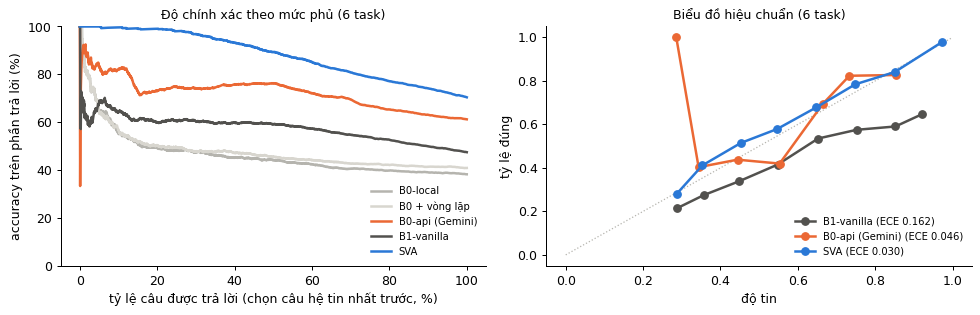

,acc @ 50%,acc @ 100%,AURC,ECE
B0-local,44.209,38.229,0.536,0.045
B0 + vòng lặp,45.647,40.878,0.520,0.049
B0-api (Gemini),76.306,61.204,0.278,0.046
B1-vanilla,59.122,47.464,0.425,0.162
SVA,89.326,70.401,0.120,0.030


In [6]:
rc = json.loads((TABLES / "risk_coverage.json").read_text(encoding="utf-8"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for n in SYSTEMS:
    c = rc[f"tất cả|{n}"]
    axes[0].plot(np.array(c["coverage"]) * 100, np.array(c["accuracy"]) * 100, color=COLORS[n], lw=2, label=n)
axes[0].set_xlabel("tỷ lệ câu được trả lời (chọn câu hệ tin nhất trước, %)"); axes[0].set_ylabel("accuracy trên phần trả lời (%)")
axes[0].set_ylim(0, 100); axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Độ chính xác theo mức phủ (6 task)", fontsize=10)
axes[1].plot([0, 1], [0, 1], color=GRAY, ls=":", lw=1)
for n in ["B1-vanilla", "B0-api (Gemini)", "SVA"]:
    rel = reliability([r for t in TASK_IDS for r in P[n][t]])
    axes[1].plot([c for c, _, _ in rel], [a for _, a, _ in rel], marker="o", color=COLORS[n], lw=2,
                 label=f"{n} (ECE {rc[f'tất cả|{n}']['ece']:.3f})")
axes[1].set_xlabel("độ tin"); axes[1].set_ylabel("tỷ lệ đúng"); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Biểu đồ hiệu chuẩn (6 task)", fontsize=10)
plt.tight_layout(); plt.show()
pd.DataFrame({n: {"acc @ 50%": 100 * rc[f"tất cả|{n}"]["acc@50"], "acc @ 100%": 100 * rc[f"tất cả|{n}"]["acc@100"],
                  "AURC": rc[f"tất cả|{n}"]["aurc"], "ECE": rc[f"tất cả|{n}"]["ece"]} for n in SYSTEMS}).T.round(3)

## 4. Chi phí và thời gian

In [7]:
display(Markdown((TABLES / "cost_time.md").read_text(encoding="utf-8")))

# Chi phí và thời gian mỗi câu (tập test, Qwen2.5-VL-3B-Instruct 4-bit)

Thời gian = độ trễ đo khi chạy (giây/câu), **chưa gồm** giải mã frame (cache dùng chung cho mọi hệ); SVA lấy lần chạy đầu (chưa có cache phân phối sự kiện của câu bình luận). Lượt gọi model là ước lượng theo cấu trúc của từng hệ.

| Task | B0-local: giây / lượt gọi | B0 + vòng lặp: giây / lượt gọi | B0-api (Gemini): giây / lượt gọi | B1-vanilla: giây / lượt gọi | SVA: giây / lượt gọi | SVA: tính trước |
|---|---|---|---|---|---|---|
| q8 | 1,3 / 1,0 | 3,6 / 2,8 | 22,1 / 1,0 | 58,9 / 10,0 | 3,6 / 4,0 | — |
| q9 | 3,9 / 1,0 | 14,1 / 2,9 | 34,4 / 1,0 | 116,9 / 14,0 | 0,6 / 0,0 | embedding CLIP 5 clip × 24 frame ≈ 7 s |
| q10 | 1,1 / 1,0 | 3,7 / 2,7 | 32,3 / 1,0 | 24,6 / 6,0 | 0,0 / 1,0 | UniSoccer 1 clip ≈ 0,2 s |
| q11 | 1,1 / 1,0 | 4,4 / 3,1 | 49,0 / 1,0 | 23,6 / 6,0 | 0,3 / 5,0 | UniSoccer 1 clip ≈ 0,2 s |
| q13 | 1,1 / 1,0 | 4,0 / 3,1 | 65,6 / 1,0 | 33,1 / 6,0 | 3,7 / 3,1 | — |
| q14 | 11,6 / 1,0 | 28,0 / 2,4 | 46,8 / 1,0 | 30,1 / 6,0 | 5,5 / 4,6 | — |

- B0-api: gọi Gemini 3.5 Flash-Lite qua gói miễn phí (độ trễ gồm cả mạng và giới hạn tốc độ); chi phí tiền thực tế 0.
- B0-local, B1, SVA chạy tại chỗ, không tốn tiền API; dữ liệu không rời máy.
- SVA ở q9/q10/q11 gần như không gọi VLM: phần nặng là tính trước embedding / Action Classifier (cột cuối), làm một lần cho mỗi clip.


## 5. Gemini + các nhánh của SVA (bản lai)

In [8]:
display(Markdown((TABLES / "sva_gemini.md").read_text(encoding="utf-8")))

# Gemini hỏi thẳng vs Gemini + các nhánh của SVA (bản lai, không gọi API thêm)

| Task | Gemini hỏi thẳng | Gemini + SVA | thay đổi | b / c | p | phần SVA thêm vào |
|---|---|---|---|---|---|---|
| q8 | 68,9 | 66,8 | -2,1 | 26 / 32 | 0,511 | kênh camera đầu/cuối (Qwen2.5-VL-3B-Instruct 4-bit), gộp trung bình với Gemini |
| q9 | 32,5 | 78,9 | 46,4 | 148 / 18 | < 0,001 | so khớp CLIP (không cần VLM) |
| q10 | 64,4 | 87,1 | 22,7 | 201 / 42 | < 0,001 | Action Classifier (không cần VLM) |
| q11 | 70,1 | 74,3 | 4,1 | 118 / 89 | 0,052 | khớp loại sự kiện (UniSoccer + đọc chữ) |
| q13 | 48,8 | 48,8 | 0,0 | 0 / 0 | 1,000 | — (giữ Gemini) |
| q14 | 79,2 | 79,2 | 0,0 | 0 / 0 | 1,000 | — (giữ Gemini; bản đầy đủ: hỏi Gemini từng góc) |
| **trung bình** | 60,7 | 72,5 | 11,9 | | | |

Thiết kế gộp ở q8 lấy nguyên từ lựa chọn trên dev của SVA (Gemini không có số trên dev nên không chỉnh gì thêm).


## 6. Phân tích ca

In [9]:
text = (TABLES / "case_studies.md").read_text(encoding="utf-8")
display(Markdown(text[:6000] + "\n\n*(xem đủ 30 ca trong results/tables/case_studies.md)*"))

# Phân tích ca (tập test)

Chọn ngẫu nhiên (seed 0), xoay vòng qua 6 task; mỗi ca kèm chuỗi bằng chứng của SVA và chuỗi công cụ của B1.

## B1 sai, SVA đúng

**q8 #281** — How does the camera position change in the video?

- phương án: O1: From Spider camera to Main camera right.; O2: From Main camera left to Close-up behind the goal.; O3: From Close-up side staff to Close-up side staff.; O4: From Main camera left to Close-up corner.
- đáp án: O2 · SVA: O2 (độ tin 0.34) · B1: O1
- SVA `holistic`: chọn O2 (0.72) — 
- SVA `camera_switch`: chọn O2 (0.48) — dau: Main behind the goal 0.40 | cuoi: Main behind the goal 0.46
- B1: Shot Change → Camera Detection → Camera Detection → LLM · kết quả cuối: Answer: The camera position in the video is: Goal line technology camera.
Reasoning and Explanation: The Camera Detection tool identified th

**q9 #269** — The first video clip in the list is a replay. Please determine which of the next four clips is the one being played again.

- phương án: O1: The 1st one.; O2: The 2nd one.; O3: The 3rd one.; O4: The 4th one.
- đáp án: O1 · SVA: O1 (độ tin 1.00) · B1: O2
- SVA `replay_match`: chọn O1 (1.00) — O1: 0.908 (lui 0.26) | O2: 0.824 (lui 0.26) | O3: 0.836 (lui 0.22) | O4: 0.844 (lui 0.26)
- B1: Commentary Generation → Commentary Generation → Commentary Generation → Commentary Generation → Commentary Generation → LLM · kết quả cuối: Answer: The second video clip in the list is the one being played again.
Reasoning and Explanation: Based on the provided commentaries, the 

**q10 #79** — Please label the football event in this video with a category.

- phương án: O1: foul lead to penalty; O2: var; O3: shot off target; O4: ball possession
- đáp án: O3 · SVA: O3 (độ tin 0.91) · B1: O1
- SVA `action_classifier`: chọn O3 (0.95) — clearance 0.39, shot off target 0.29, lead to corner 0.08
- B1: Action Classifier → LLM · kết quả cuối: Answer: The football event in this video is labeled as "clearance".
Reasoning and Explanation: The Action Classifier tool has classified the

**q11 #360** — Generate commentary lines for this football video clip.

- phương án: O1: [PLAYER] ([TEAM]) should know this behaviour is beyond the rules. He w; O2: [REFEREE] blows his whistle and it's [PLAYER] ([TEAM]) who is penalise; O3: The defence is alert as they clear a dangerous cross from [PLAYER] ([T; O4: [PLAYER] ([TEAM]) fires the ball in from a mid-range free kick, but it
- đáp án: O4 · SVA: O4 (độ tin 0.49) · B1: O1
- SVA `event_match`: chọn O4 (0.66) — video: shot off target 0.84, free kick 0.05, corner 0.03
- B1: Commentary Generation → LLM · kết quả cuối: Answer: [Player X scores a goal.]
Reasoning and Explanation: Based on the video clip, the player scored a goal. Therefore, the commentary li

**q13 #503** — In the video, which color jersey is the player wearing who was caught offside?

- phương án: O1: blue; O2: white; O3: silver; O4: black
- đáp án: O2 · SVA: O2 (độ tin 0.35) · B1: O1
- SVA `holistic`: chọn O2 (0.54) — 
- B1: Vision Language Model → LLM · kết quả cuối: Answer: The player wearing the yellow jersey was caught offside in the video.
Reasoning and Explanation: The Vision Language Model (LLM) too

**q14 #161** — Which action category does this foul belong to?

- phương án: O1: Dive; O2: Holding; O3: Pushing; O4: Challenge
- đáp án: O4 · SVA: O4 (độ tin 0.16) · B1: O1
- SVA `multiview`: chọn O4 (0.41) — action: view0 O4 ro 0.69; view1 O4 ro 0.75
- B1: Foul Recognition → LLM · kết quả cuối: Answer: Offside
Reasoning and Explanation: The tool identified the foul as Offside based on the provided video clips and their respective sp

**q8 #290** — What kind of changes in camera positioning are there in the video?

- phương án: O1: From Close-up behind the goal to Main camera center.; O2: From Close-up behind the goal to Main behind the goal.; O3: From Spider camera to Close-up side staff.; O4: From Close-up corner to Spider camera.
- đáp án: O1 · SVA: O1 (độ tin 0.53) · B1: O3
- SVA `holistic`: chọn O1 (0.48) — 
- SVA `camera_switch`: chọn O1 (0.89) — dau: Main behind the goal 0.34 | cuoi: Main camera center 0.65
- B1: Shot Change → Camera Detection → Camera Detection → LLM · kết quả cuối: Answer: The camera position in the video is: Main camera center.
Reasoning and Explanation: The Camera Detection tool identified three scene

**q9 #209** — You are provided with five video clips, the first of which is a replay clip. Please determine which of the following four video clips it is a replay of?

- phương án: O1: The 1st one.; O2: The 2nd one.; O3: The 3rd one.; O4: The 4th one.
- đáp án: O2 · SVA: O2 (độ tin 0.68) · B1: O1
- SVA `replay_match`: chọn O2 (0.81) — O1: 0.834 (lui 0.39) | O2: 0.852 (lui 0.26) | O3: 0.821 (lui 0.35) | O4: 0.818 (lui 0.35)
- B1: Commentary Generation → Commentary Generation → Commentary Generation → Commentary Generation → Commentary Generation → LLM · kết quả cuối: Answer: None
Reasoning and Explanation: None of the video clips provided have a commentary that matches the criteria of being a replay of th

**q10 #678** — Choose a category for the football scene in this video.

- phương án: O1: var; O2: start of half game; O3: yellow card; O4: throw in
- đáp án: O3 · SVA: O3 (độ tin 0.97) · B1: O1
- SVA `action_classifier`: chọn O3 (0.98) — free kick 0.83, yellow card 0.07, ball out of play 0.04
- B1: Action Classifier → LLM · kết quả cuối: Answer: The category for the football scene in this video is "free kick".
Reasoning and Explanation: Based on the classification probabiliti

**q11 #532** — Write a commentary description for this football video.

- phương án: O1: Here is a change. [PLAYER] is going off and [PLAYER] gives the last ta; O2: 3 min. of stoppage-time to be played.; O3: [PLAYER] has decided to substitute [PLAYER] and he is replaced by [PLA; O4: [PLAYER] ([TEAM]) takes the free kick which is inaccurate and the defe
- đáp án: O4 · SVA: O4 (độ tin 0.58) · B1: O3
- SVA `event_match`: chọn O4 (0.77) — video: lead to corner 0.44, corner 0.

*(xem đủ 30 ca trong results/tables/case_studies.md)*

## 7. Bản 3B và bản 7B (A6)

In [10]:
SYS = {"B0": "b0_local", "B0 + vòng lặp": "b0_loop", "B1": "b1_vanilla", "SVA": "sva"}
name = lambda s, size: s if size == "3B" else f"{s}_7b"
acc = {(k, size, t): 100 * accuracy(load_predictions(name(v, size), t)) for k, v in SYS.items() for size in ("3B", "7B") for t in TASK_IDS}
gem = {t: 100 * accuracy(load_predictions("b0_api", t)) for t in TASK_IDS}
f = lambda x: f"{x:.1f}".replace(".", ",")
rows = ["| hệ | cỡ | " + " | ".join(TASK_IDS) + " | TB |", "|---|---|" + "---|" * 7]
for k in SYS:
    for size in ("3B", "7B"):
        v = [acc[(k, size, t)] for t in TASK_IDS]
        rows.append(f"| {k} | {size} | " + " | ".join(f(x) for x in v) + f" | **{f(np.mean(v))}** |")
rows.append("| Gemini hỏi thẳng | — | " + " | ".join(f(gem[t]) for t in TASK_IDS) + f" | {f(np.mean(list(gem.values())))} |")
display(Markdown("\n".join(rows)))

| hệ | cỡ | q8 | q9 | q10 | q11 | q13 | q14 | TB |
|---|---|---|---|---|---|---|---|---|
| B0 | 3B | 45,4 | 27,5 | 36,1 | 31,3 | 45,9 | 56,8 | **40,5** |
| B0 | 7B | 54,3 | 24,3 | 45,4 | 44,6 | 45,1 | 63,0 | **46,1** |
| B0 + vòng lặp | 3B | 52,5 | 25,0 | 37,4 | 37,9 | 46,1 | 57,3 | **42,7** |
| B0 + vòng lặp | 7B | 60,4 | 24,3 | 48,4 | 47,9 | 48,2 | 65,6 | **49,1** |
| B1 | 3B | 45,0 | 25,7 | 74,6 | 31,4 | 46,3 | 45,3 | **44,7** |
| B1 | 7B | 52,5 | 23,6 | 79,7 | 37,0 | 43,3 | 52,6 | **48,1** |
| SVA | 3B | 58,9 | 78,9 | 87,1 | 74,3 | 46,5 | 60,4 | **67,7** |
| SVA | 7B | 69,3 | 78,9 | 87,1 | 72,0 | 48,4 | 64,1 | **70,0** |
| Gemini hỏi thẳng | — | 68,9 | 32,5 | 64,4 | 70,1 | 48,8 | 79,2 | 60,7 |

### 7.1 Mỗi hệ khi đổi 3B → 7B

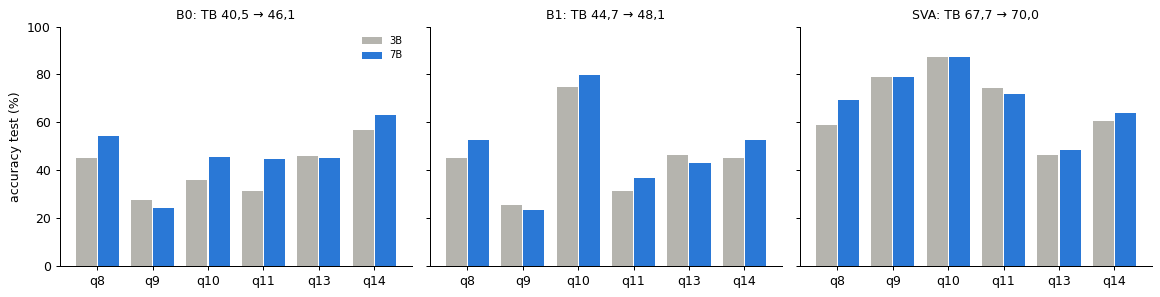

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
x = np.arange(len(TASK_IDS))
for ax, k in zip(axes, ("B0", "B1", "SVA")):
    a = [acc[(k, "3B", t)] for t in TASK_IDS]
    b = [acc[(k, "7B", t)] for t in TASK_IDS]
    ax.bar(x - 0.2, a, 0.38, color=GRAY, label="3B")
    ax.bar(x + 0.2, b, 0.38, color=BLUE, label="7B")
    ax.set_xticks(x, TASK_IDS)
    ax.set_title(f"{k}: TB {f(np.mean(a))} → {f(np.mean(b))}", fontsize=10)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("accuracy test (%)")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 7.2 Khoảng cách SVA − B1

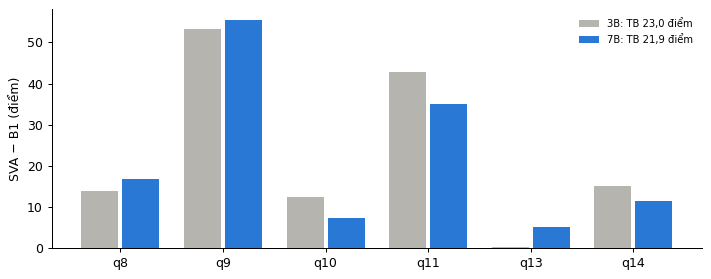

3B: SVA hơn B1 có ý nghĩa (McNemar p < 0,05) ở 5/6 tác vụ: ['q8', 'q9', 'q10', 'q11', 'q14']


7B: SVA hơn B1 có ý nghĩa (McNemar p < 0,05) ở 6/6 tác vụ: ['q8', 'q9', 'q10', 'q11', 'q13', 'q14']


In [12]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for j, (size, color) in enumerate((("3B", GRAY), ("7B", BLUE))):
    d = [acc[("SVA", size, t)] - acc[("B1", size, t)] for t in TASK_IDS]
    ax.bar(x + (j - 0.5) * 0.4, d, 0.36, color=color, label=f"{size}: TB {f(np.mean(d))} điểm")
ax.axhline(0, color=DARK, lw=0.8)
ax.set_xticks(x, TASK_IDS); ax.set_ylabel("SVA − B1 (điểm)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
for size in ("3B", "7B"):
    sig = [t for t in TASK_IDS if mcnemar(load_predictions(name("b1_vanilla", size), t), load_predictions(name("sva", size), t))["p_value"] < 0.05]
    print(f"{size}: SVA hơn B1 có ý nghĩa (McNemar p < 0,05) ở {len(sig)}/6 tác vụ: {sig}")

### 7.3 Ablation A1, A5 ở hai cỡ model

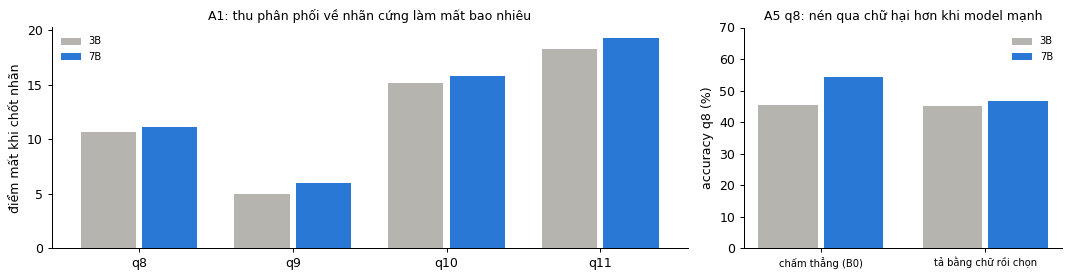

In [13]:
def ablation(path):
    text = (RESULTS_DIR / "tables" / path).read_text(encoding="utf-8")
    out = {}
    for block in text.split("## ")[1:]:
        title = block.split("\n")[0]
        vals = re.findall(r"^\| ([^|]+) \| \d+ \| ([\d,]+) \|", block, flags=re.M)
        out[title] = {k.strip("* "): float(v.replace(",", ".")) for k, v in vals}
    return out
A = {"3B": ablation("ablation_test.md"), "7B": ablation("ablation_test_7b.md")}
loss = {size: [] for size in A}
tasks = ("q8", "q9", "q10", "q11")
for size in A:
    for t in tasks:
        d = next(v for k, v in A[size].items() if k.startswith(f"A1 · {t}:"))
        vals = list(d.values())
        loss[size].append(vals[0] - vals[1])
a5 = {size: next(v for k, v in A[size].items() if k.startswith("A5 · q8")) for size in A}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1]})
xx = np.arange(len(tasks))
for j, (size, color) in enumerate((("3B", GRAY), ("7B", BLUE))):
    axes[0].bar(xx + (j - 0.5) * 0.4, loss[size], 0.36, color=color, label=size)
axes[0].set_xticks(xx, tasks); axes[0].set_ylabel("điểm mất khi chốt nhãn")
axes[0].set_title("A1: thu phân phối về nhãn cứng làm mất bao nhiêu", fontsize=10); axes[0].legend(frameon=False, fontsize=8)
labels = ["chấm thẳng (B0)", "tả bằng chữ rồi chọn"]
for j, (size, color) in enumerate((("3B", GRAY), ("7B", BLUE))):
    v = list(a5[size].values())[:2]
    axes[1].bar(np.arange(2) + (j - 0.5) * 0.4, v, 0.36, color=color, label=size)
axes[1].set_xticks(range(2), labels, fontsize=8); axes[1].set_ylim(0, 70); axes[1].set_ylabel("accuracy q8 (%)")
axes[1].set_title("A5 q8: nén qua chữ hại hơn khi model mạnh", fontsize=10); axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### 7.4 Độ tin cậy bản 7B

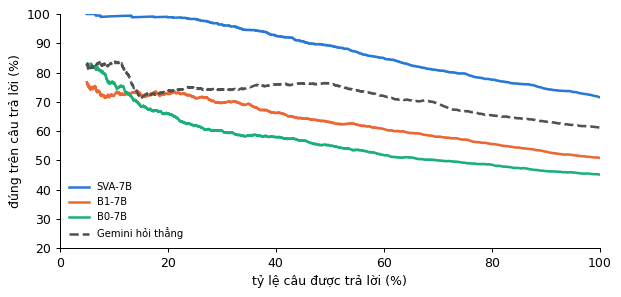

In [14]:
def curve(n):
    pool = sorted([(r.get("confidence", max(r["dist"].values())), correct(r)) for t in TASK_IDS for r in load_predictions(n, t)],
                  key=lambda z: -z[0])
    c = np.cumsum([z[1] for z in pool]) / np.arange(1, len(pool) + 1)
    return 100 * np.arange(1, len(pool) + 1) / len(pool), 100 * c
fig, ax = plt.subplots(figsize=(7, 3.4))
for n, label, color, ls in (("sva_7b", "SVA-7B", BLUE, "-"), ("b1_vanilla_7b", "B1-7B", ORANGE, "-"),
                            ("b0_local_7b", "B0-7B", AQUA, "-"), ("b0_api", "Gemini hỏi thẳng", DARK, "--")):
    cov, a = curve(n)
    keep = cov >= 5                                  # bo vai phan tram dau (qua it cau, dao dong manh)
    ax.plot(cov[keep], a[keep], color=color, lw=2, ls=ls, label=label)
ax.set_xlim(0, 100); ax.set_xlabel("tỷ lệ câu được trả lời (%)"); ax.set_ylabel("đúng trên câu trả lời (%)"); ax.set_ylim(20, 100)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()